In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sentence_transformers import SentenceTransformer

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)

C:\Users\Dell\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
DATA_PATH = r"C:\Users\Dell\Desktop\Adam\NLP Projects\AIOps Incident Triage\data\raw\tickets_clean.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()

Dataset shape: (9980, 15)

Columns:
['ticket_id', 'created_date', 'resolved_date', 'category', 'sub_category', 'priority', 'status', 'subject', 'description', 'resolution', 'product_service', 'department', 'satisfaction_rating', 'time_to_resolution_hours', 'text_length']


,ticket_id,created_date,resolved_date,category,sub_category,priority,status,subject,description,resolution,product_service,department,satisfaction_rating,time_to_resolution_hours,text_length
0,TKT-10001,2025-05-09 00:00,2025-05-09 02:12,Access/Permissions,Account Lockout,Critical,Resolved,Account locked after password change,"hi there, changed my password yesterday and no...",Account lockout was caused by mobile devices t...,Azure AD,Logistics,4.0,2.2,296
1,TKT-10002,2023-09-13 00:00,2023-09-13 07:48,Security,Malware,Critical,Closed,USB drive triggered security alert,plugged in a usb drive i got at a conference a...,USB contained autorun malware that was caught ...,Palo Alto Cortex,Customer Support,3.0,7.8,245
2,TKT-10003,2025-01-28 00:00,2025-01-28 03:12,Hardware,Desktop,Critical,Closed,Need more RAM — computer too slow with current...,my macbook pro m3 only has 8gb ram and i regul...,Approved RAM upgrade request. Installed additi...,MacBook Pro M3,Product,3.0,3.2,323
3,TKT-10004,2024-10-08 00:00,NaN,Cloud/Infrastructure,VM,Critical,Open,Need to resize VM — running out of resources,our staging vm needs to be upgraded — currentl...,NaN,Azure Blob Storage,Human Resources,NaN,NaN,264
4,TKT-10005,2025-01-11 00:00,2025-01-12 19:06,Hardware,Desktop,Low,Closed,Need more RAM — computer too slow with current...,my dell precision 5570 only has 8gb ram and i ...,Approved RAM upgrade request. Installed additi...,Dell Precision 5570,Customer Support,3.0,43.1,280


In [3]:
TARGET = "priority"
TEXT_COLUMNS = ["subject", "description"]

required_columns = [TARGET, *TEXT_COLUMNS, "created_date"]

missing_columns = [
    column
    for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

df["created_date"] = pd.to_datetime(
    df["created_date"],
    errors="coerce"
)

df = df.dropna(
    subset=["created_date", TARGET]
).copy()

df[TARGET] = df[TARGET].astype(str).str.strip()

df = df[
    df[TARGET].isin(
        ["Critical", "High", "Medium", "Low"]
    )
].copy()

# Replace missing text with empty strings.
# Do not remove rows merely because a text field is missing.
for column in TEXT_COLUMNS:
    df[column] = df[column].fillna("").astype(str)

# Ensure a deterministic chronological order.
df = df.sort_values(
    "created_date",
    kind="stable"
).reset_index(drop=True)

print("Prepared dataset shape:", df.shape)
print("\nPriority distribution:")
print(df[TARGET].value_counts())

Prepared dataset shape: (9980, 15)

Priority distribution:
priority
Medium      3846
Low         2515
High        2309
Critical    1310
Name: count, dtype: int64


In [4]:
train_size = 0.8
split_index = int(len(df) * train_size)

train_df = df.iloc[:split_index].copy()
test_df = df.iloc[split_index:].copy()

X_train = train_df[TEXT_COLUMNS].copy()
y_train = train_df[TARGET].copy()

X_test = test_df[TEXT_COLUMNS].copy()
y_test = test_df[TARGET].copy()

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print(
    "Training date range:",
    train_df["created_date"].min(),
    "to",
    train_df["created_date"].max()
)

print(
    "Testing date range:",
    test_df["created_date"].min(),
    "to",
    test_df["created_date"].max()
)

print("\nTraining priority distribution:")
print(y_train.value_counts(normalize=True).sort_index().round(3))

print("\nTesting priority distribution:")
print(y_test.value_counts(normalize=True).sort_index().round(3))

Training samples: 7984
Testing samples: 1996
Training date range: 2023-01-01 00:00:00 to 2025-06-01 00:00:00
Testing date range: 2025-06-01 00:00:00 to 2025-12-31 00:00:00

Training priority distribution:
priority
Critical    0.135
High        0.232
Low         0.246
Medium      0.387
Name: proportion, dtype: float64

Testing priority distribution:
priority
Critical    0.116
High        0.229
Low         0.275
Medium      0.380
Name: proportion, dtype: float64


In [5]:
MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"

model = SentenceTransformer(MODEL_NAME)

def combine_text(data):
    subject = data["subject"].str.strip()
    description = data["description"].str.strip()

    return (
        "Subject: " + subject
        + " [SEP] Description: " + description
    ).tolist()


train_text = combine_text(X_train)
test_text = combine_text(X_test)

X_train_embeddings = model.encode(
    train_text,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=False,
)

X_test_embeddings = model.encode(
    test_text,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=False,
)

print("Training embeddings shape:", X_train_embeddings.shape)
print("Testing embeddings shape:", X_test_embeddings.shape)

Batches: 100%|██████████| 63/63 [00:37<00:00,  1.69it/s]

Training embeddings shape: (7984, 384)
Testing embeddings shape: (1996, 384)


In [6]:
text_model = LogisticRegression(
    C=1.0,
    max_iter=2000,
    class_weight=None,
    random_state=42,
)

text_model.fit(
    X_train_embeddings,
    y_train
)

print("Text-only model training completed.")

Text-only model training completed.


In [7]:
train_predictions = text_model.predict(
    X_train_embeddings
)

test_predictions = text_model.predict(
    X_test_embeddings
)

In [8]:
print("========== TEXT-ONLY TRAINING PERFORMANCE ==========")

print(
    "Accuracy:",
    accuracy_score(y_train, train_predictions)
)

print(
    "Weighted F1:",
    f1_score(
        y_train,
        train_predictions,
        average="weighted",
        zero_division=0,
    )
)

print(
    "Macro F1:",
    f1_score(
        y_train,
        train_predictions,
        average="macro",
        zero_division=0,
    )
)

print("\n========== TEXT-ONLY TEST PERFORMANCE ==========")

print(
    "Accuracy:",
    accuracy_score(y_test, test_predictions)
)

print(
    "Weighted F1:",
    f1_score(
        y_test,
        test_predictions,
        average="weighted",
        zero_division=0,
    )
)

print(
    "Macro F1:",
    f1_score(
        y_test,
        test_predictions,
        average="macro",
        zero_division=0,
    )
)

print("\nClassification report:")

print(
    classification_report(
        y_test,
        test_predictions,
        labels=["Critical", "High", "Low", "Medium"],
        zero_division=0,
    )
)

========== TEXT-ONLY TRAINING PERFORMANCE ==========
Accuracy: 0.7153056112224448
Weighted F1: 0.7085230910735152
Macro F1: 0.6951705529462971

========== TEXT-ONLY TEST PERFORMANCE ==========
Accuracy: 0.6998997995991983
Weighted F1: 0.6921329394055816
Macro F1: 0.669708734038887

Classification report:
              precision    recall  f1-score   support

    Critical       0.80      0.49      0.61       231
        High       0.68      0.52      0.59       457
         Low       0.77      0.70      0.74       549
      Medium       0.66      0.87      0.75       759

    accuracy                           0.70      1996
   macro avg       0.73      0.65      0.67      1996
weighted avg       0.71      0.70      0.69      1996



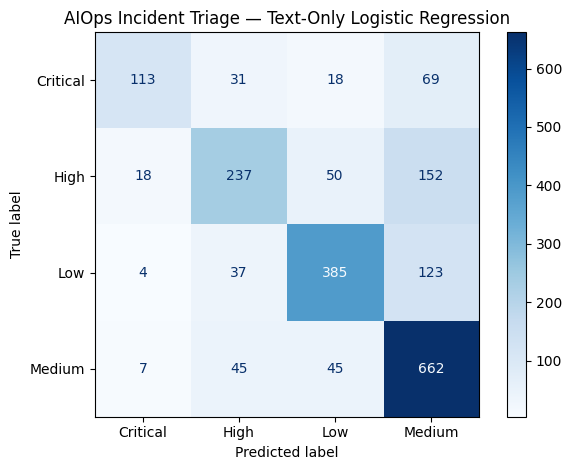

In [9]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=["Critical", "High", "Low", "Medium"],
    cmap="Blues",
    values_format="d",
)

plt.title("AIOps Incident Triage — Text-Only Logistic Regression")
plt.tight_layout()
plt.show()

In [10]:
text_only_results = {
    "Experiment": "Text only - Logistic Regression",
    "Train Accuracy": accuracy_score(
        y_train, train_predictions
    ),
    "Test Accuracy": accuracy_score(
        y_test, test_predictions
    ),
    "Train Macro F1": f1_score(
        y_train,
        train_predictions,
        average="macro",
        zero_division=0,
    ),
    "Test Macro F1": f1_score(
        y_test,
        test_predictions,
        average="macro",
        zero_division=0,
    ),
    "Test Weighted F1": f1_score(
        y_test,
        test_predictions,
        average="weighted",
        zero_division=0,
    ),
}

pd.DataFrame([text_only_results])

,Experiment,Train Accuracy,Test Accuracy,Train Macro F1,Test Macro F1,Test Weighted F1
0,Text only - Logistic Regression,0.715306,0.6999,0.695171,0.669709,0.692133


In [ ]:
##############################
# Fitting a Model on Tabular Features Only

In [11]:
TABULAR_FEATURES = [
    "category",
    "sub_category",
    "department"
]

TARGET = "priority"

# Reuse the same chronological split as the text-only experiment
train_df = df.iloc[:split_index].copy()
test_df = df.iloc[split_index:].copy()

X_train_tabular = train_df[TABULAR_FEATURES].copy()
X_test_tabular = test_df[TABULAR_FEATURES].copy()

y_train_tabular = train_df[TARGET].copy()
y_test_tabular = test_df[TARGET].copy()

print("Training shape:", X_train_tabular.shape)
print("Testing shape:", X_test_tabular.shape)

print("\nTraining target distribution:")
print(y_train_tabular.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test_tabular.value_counts(normalize=True))

Training shape: (7984, 3)
Testing shape: (1996, 3)

Training target distribution:
priority
Medium      0.386648
Low         0.246242
High        0.231964
Critical    0.135145
Name: proportion, dtype: float64

Testing target distribution:
priority
Medium      0.380261
Low         0.275050
High        0.228958
Critical    0.115731
Name: proportion, dtype: float64


In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

categorical_features = TABULAR_FEATURES

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            categorical_transformer,
            categorical_features
        )
    ]
)

tabular_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                C=1.0,
                max_iter=2000,
                class_weight=None,
                random_state=42
            )
        )
    ]
)

In [13]:
tabular_model.fit(X_train_tabular, y_train_tabular)

train_predictions = tabular_model.predict(X_train_tabular)
test_predictions = tabular_model.predict(X_test_tabular)

print("Model training completed.")

Model training completed.


In [14]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

print("========== TABULAR-ONLY TRAINING PERFORMANCE ==========")
print("Accuracy:", accuracy_score(y_train_tabular, train_predictions))
print(
    "Weighted F1:",
    f1_score(y_train_tabular, train_predictions, average="weighted")
)
print(
    "Macro F1:",
    f1_score(y_train_tabular, train_predictions, average="macro")
)

print("\n========== TABULAR-ONLY TEST PERFORMANCE ==========")
print("Accuracy:", accuracy_score(y_test_tabular, test_predictions))
print(
    "Weighted F1:",
    f1_score(y_test_tabular, test_predictions, average="weighted")
)
print(
    "Macro F1:",
    f1_score(y_test_tabular, test_predictions, average="macro")
)

print("\nClassification report:")
print(
    classification_report(
        y_test_tabular,
        test_predictions,
        labels=["Critical", "High", "Low", "Medium"],
        zero_division=0
    )
)

========== TABULAR-ONLY TRAINING PERFORMANCE ==========
Accuracy: 0.4561623246492986
Weighted F1: 0.41806797447973587
Macro F1: 0.3877333065314035

========== TABULAR-ONLY TEST PERFORMANCE ==========
Accuracy: 0.4408817635270541
Weighted F1: 0.40333759959619114
Macro F1: 0.37369269475294287

Classification report:
              precision    recall  f1-score   support

    Critical       0.52      0.21      0.30       231
        High       0.49      0.29      0.36       457
         Low       0.51      0.20      0.29       549
      Medium       0.42      0.77      0.54       759

    accuracy                           0.44      1996
   macro avg       0.48      0.37      0.37      1996
weighted avg       0.47      0.44      0.40      1996



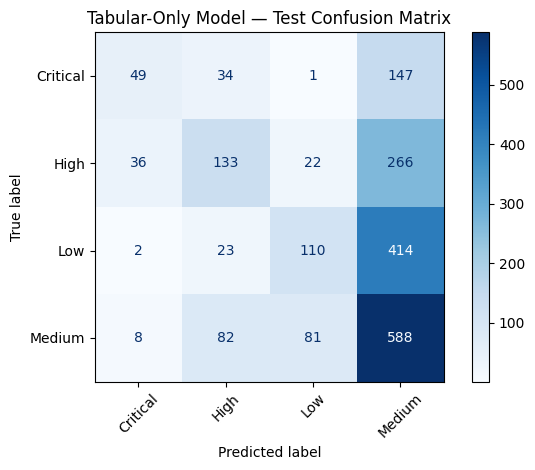

In [15]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

class_labels = ["Critical", "High", "Low", "Medium"]

ConfusionMatrixDisplay.from_predictions(
    y_test_tabular,
    test_predictions,
    labels=class_labels,
    display_labels=class_labels,
    cmap="Blues",
    values_format="d"
)

plt.title("Tabular-Only Model — Test Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
tabular_results = {
    "Model": "Tabular-only Logistic Regression",
    "Train Accuracy": accuracy_score(
        y_train_tabular, train_predictions
    ),
    "Test Accuracy": accuracy_score(
        y_test_tabular, test_predictions
    ),
    "Train Weighted F1": f1_score(
        y_train_tabular, train_predictions, average="weighted"
    ),
    "Test Weighted F1": f1_score(
        y_test_tabular, test_predictions, average="weighted"
    ),
    "Train Macro F1": f1_score(
        y_train_tabular, train_predictions, average="macro"
    ),
    "Test Macro F1": f1_score(
        y_test_tabular, test_predictions, average="macro"
    )
}

import pandas as pd

pd.DataFrame([tabular_results])

,Model,Train Accuracy,Test Accuracy,Train Weighted F1,Test Weighted F1,Train Macro F1,Test Macro F1
0,Tabular-only Logistic Regression,0.456162,0.440882,0.418068,0.403338,0.387733,0.373693
